# 02 Trend and seasonality (BQ1, BQ2): Python version

**BQ1:** How have revenue, orders and active customers changed over the two years?
**BQ2:** What repeats by month, weekday and hour?

Same questions and data as `02_trend_seasonality_r.ipynb`; the results must agree.
Input: `data/processed/` from `src/clean_data.py`. Revenue = net product revenue
(gross product sales − product cancellations), per docs/02.

## Setup and data

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

sales = pd.read_parquet(PROC / "sales_clean.parquet")
cancels = pd.read_parquet(PROC / "cancellations.parquet")

prod = sales.loc[sales["line_type"] == "product"].copy()      # T6
canc = cancels.loc[cancels["line_type"] == "product"].copy()  # T5
print(f"Product sales lines: {len(prod):,}   product cancellation lines: {len(canc):,}")
print("Period:", prod["date"].min().date(), "to", prod["date"].max().date())

Product sales lines: 1,003,357   product cancellation lines: 17,915
Period: 2009-12-01 to 2011-12-09


## KPI tables
Orders and order value exclude orders that were later cancelled (T5); net revenue subtracts all product cancellations. The weekly series uses a complete calendar, with closed weeks set to zero.

In [3]:
def kpis(period_col):
    """Net revenue, orders, customers and order value per period."""
    g = prod.groupby(period_col).agg(
        gross_sales=("revenue", "sum"),
        customers=("customer_id", "nunique"))
    kept = prod.loc[~prod["cancelled_exact"]]
    k = kept.groupby(period_col).agg(kept_sales=("revenue", "sum"),
                                     orders=("invoice", "nunique"))
    g = g.join(k)
    g["cancellations"] = (-canc.groupby(period_col)["revenue"].sum()).reindex(g.index).fillna(0)
    g["net_revenue"] = g["gross_sales"] - g["cancellations"]
    g["avg_order_value"] = g["kept_sales"] / g["orders"]
    g["cancel_rate"] = g["cancellations"] / g["gross_sales"]
    return g

monthly = kpis("month")
monthly = monthly.loc[monthly.index < "2011-12-01"]          # T10

# Weekly series on a complete calendar: weeks with no sales (Christmas closures)
# would otherwise be missing and shift every later week
weekly = kpis("week_start")
all_weeks = pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-MON")
closed = all_weeks.difference(weekly.index)
weekly = weekly.reindex(all_weeks)
sums = ["gross_sales", "customers", "kept_sales", "orders", "cancellations", "net_revenue"]
weekly[sums] = weekly[sums].fillna(0)
weekly = weekly.iloc[1:-1]                                    # drop partial weeks

print(f"Complete months: {len(monthly)}   complete weeks: {len(weekly)}")
print("Weeks with no sales:", [d.date().isoformat() for d in closed])
monthly[["net_revenue", "orders", "customers", "avg_order_value", "cancel_rate"]]

Complete months: 24   complete weeks: 104
Weeks with no sales: ['2009-12-28', '2010-12-27']


,net_revenue,orders,customers,avg_order_value,cancel_rate
month,,,,,
2009-12-01,"778,343.08",1660,951,476.35,0.02
2010-01-01,"604,831.79",1040,701,584.71,0.01
2010-02-01,"525,334.24",1177,771,449.20,0.02
2010-03-01,"752,102.13",1635,1051,461.16,0.01
2010-04-01,"636,315.67",1428,939,446.31,0.02
2010-05-01,"606,299.14",1474,965,427.24,0.06
2010-06-01,"670,209.73",1604,1034,422.20,0.04
2010-07-01,"615,861.59",1493,924,415.47,0.03
2010-08-01,"661,640.12",1394,910,469.08,0.02


## BQ1: Year on year and growth decomposition
Year 1 = Dec 2009 – Nov 2010, Year 2 = Dec 2010 – Nov 2011. Growth is split in log points, which works even when total growth is close to zero.

In [4]:
y1 = monthly.loc["2009-12-01":"2010-11-01"]
y2 = monthly.loc["2010-12-01":"2011-11-01"]
summary = pd.DataFrame({
    "Year 1 (Dec09-Nov10)": [y1["net_revenue"].sum(), y1["orders"].sum(), y1["avg_order_value"].mean()],
    "Year 2 (Dec10-Nov11)": [y2["net_revenue"].sum(), y2["orders"].sum(), y2["avg_order_value"].mean()],
}, index=["Net revenue (GBP)", "Orders", "Avg order value (GBP, monthly mean)"])
summary["Change"] = summary.iloc[:, 1] / summary.iloc[:, 0] - 1
print(summary.to_string(formatters={"Change": "{:+.1%}".format}))

c1 = prod.loc[prod["month"].between("2009-12-01", "2010-11-01"), "customer_id"].nunique()
c2 = prod.loc[prod["month"].between("2010-12-01", "2011-11-01"), "customer_id"].nunique()
print(f"\nActive customers: {c1:,} -> {c2:,} ({c2 / c1 - 1:+.1%})")

rev1, rev2 = y1["kept_sales"].sum(), y2["kept_sales"].sum()
o1, o2 = y1["orders"].sum(), y2["orders"].sum()
lp = lambda a, b: 100 * np.log(b / a)
print(f"\nSales of kept orders: {rev2 / rev1 - 1:+.1%}  = {lp(rev1, rev2):+.1f} log points, of which:")
print(f"  orders              {lp(o1, o2):+.1f} log points ({o2 / o1 - 1:+.1%})")
print(f"  value per order     {lp(rev1 / o1, rev2 / o2):+.1f} log points "
      f"({(rev2 / o2) / (rev1 / o1) - 1:+.1%})")

                                     Year 1 (Dec09-Nov10)  Year 2 (Dec10-Nov11) Change
Net revenue (GBP)                            9,156,080.90          9,330,918.60  +1.9%
Orders                                          19,603.00             18,837.00  -3.9%
Avg order value (GBP, monthly mean)                469.22                493.04  +5.1%

Active customers: 4,239 -> 4,293 (+1.3%)

Sales of kept orders: +1.7%  = +1.7 log points, of which:
  orders              -4.0 log points (-3.9%)
  value per order     +5.7 log points (+5.9%)


## BQ1: Weekly net revenue with moving averages

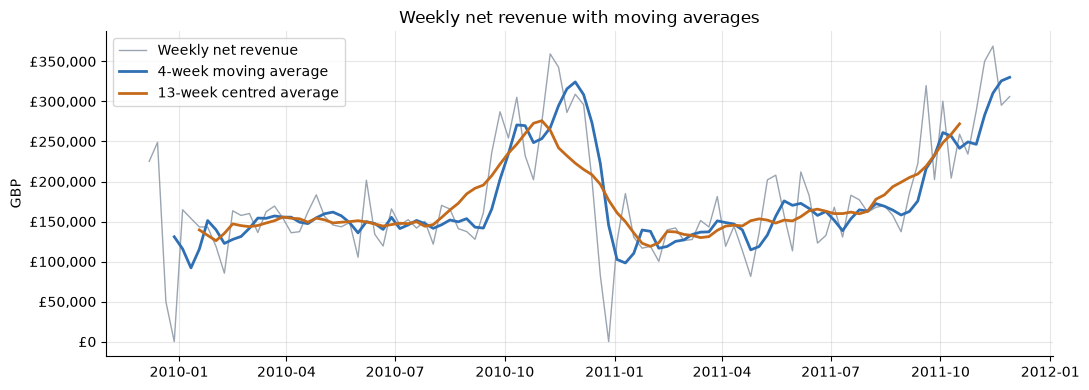

In [5]:
w = weekly["net_revenue"]
fig, ax = plt.subplots()
ax.plot(w.index, w, color="#9AA5B1", lw=1, label="Weekly net revenue")
ax.plot(w.index, w.rolling(4).mean(), color="#2F6FB3", lw=2, label="4-week moving average")
ax.plot(w.index, w.rolling(13, center=True).mean(), color="#C46A1A", lw=2, label="13-week centred average")
ax.set_title("Weekly net revenue with moving averages")
ax.set_ylabel("GBP")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "bq1_weekly_revenue.png", dpi=150)
plt.show()

## BQ1: Trend regression with HAC (Newey-West) standard errors
The naive trend and the Q4-only control are kept on purpose: they show how seasonality distorts a simple trend line.

In [6]:
# t counts every calendar week; weeks with no sales are then left out of the log model
trend_df = pd.DataFrame({"net": w, "t": np.arange(len(w))}, index=w.index)
trend_df = trend_df.loc[trend_df["net"] > 0].assign(log_rev=lambda x: np.log(x["net"]))
print("Weeks used in the log regression:", len(trend_df))
X = sm.add_constant(trend_df["t"])
naive = sm.OLS(trend_df["log_rev"], X).fit()
robust = sm.OLS(trend_df["log_rev"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
slope = robust.params["t"]
print(robust.summary().tables[1])
print(f"\nTrend: {np.exp(slope) - 1:+.2%} per week = {np.exp(slope * 52) - 1:+.1%} per year")
print(f"p-value, naive OLS: {naive.pvalues['t']:.4f}   HAC robust: {robust.pvalues['t']:.4f}")

trend_df["q4"] = trend_df.index.month.isin([10, 11, 12]).astype(int)
adj = sm.OLS(trend_df["log_rev"], sm.add_constant(trend_df[["t", "q4"]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4})
print(f"Trend with Q4 control: {np.exp(adj.params['t'] * 52) - 1:+.1%} per year "
      f"(p = {adj.pvalues['t']:.4f});  Q4 uplift: {np.exp(adj.params['q4']) - 1:+.1%}")

Weeks used in the log regression: 102
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         11.8422      0.073    162.206      0.000      11.699      11.985
t              0.0037      0.001      2.509      0.012       0.001       0.007

Trend: +0.38% per week = +21.5% per year
p-value, naive OLS: 0.0013   HAC robust: 0.0121
Trend with Q4 control: +14.6% per year (p = 0.0126);  Q4 uplift: +56.2%


## BQ1: Trend with month-of-year controls and moving annual total
A dummy for every month removes the seasonal confounding; the moving annual total covers a full year of seasons in every point.

Trend with month-of-year controls: +2.1% per year (p = 0.520)
Moving annual total: £9,078,831 (2010-11-29) -> £9,283,162 (2011-11-28), +2.3%


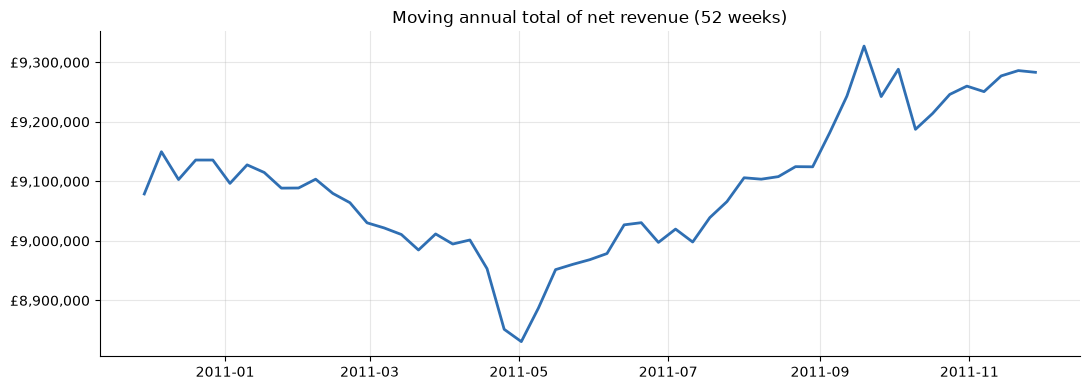

In [7]:
df_fe = pd.DataFrame({"net": w, "t": np.arange(len(w)),
                      "moy": w.index.month.astype(str)}, index=w.index)
df_fe = df_fe.loc[df_fe["net"] > 0].assign(log_rev=lambda x: np.log(x["net"]))
fe = smf.ols("log_rev ~ t + C(moy)", data=df_fe).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(f"Trend with month-of-year controls: {np.exp(fe.params['t'] * 52) - 1:+.1%} per year "
      f"(p = {fe.pvalues['t']:.3f})")

mat = w.rolling(52).sum().dropna()
print(f"Moving annual total: £{mat.iloc[0]:,.0f} ({mat.index[0].date()}) -> "
      f"£{mat.iloc[-1]:,.0f} ({mat.index[-1].date()}), {mat.iloc[-1] / mat.iloc[0] - 1:+.1%}")

fig, ax = plt.subplots()
ax.plot(mat.index, mat, color="#2F6FB3", lw=2)
ax.set_title("Moving annual total of net revenue (52 weeks)")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
fig.tight_layout(); fig.savefig(FIG / "bq1_moving_annual_total.png", dpi=150)
plt.show()

## BQ2: STL decomposition
With only two yearly cycles, STL overfits (residuals close to zero), so strength measures are not meaningful. The trend line is a rough guide only.

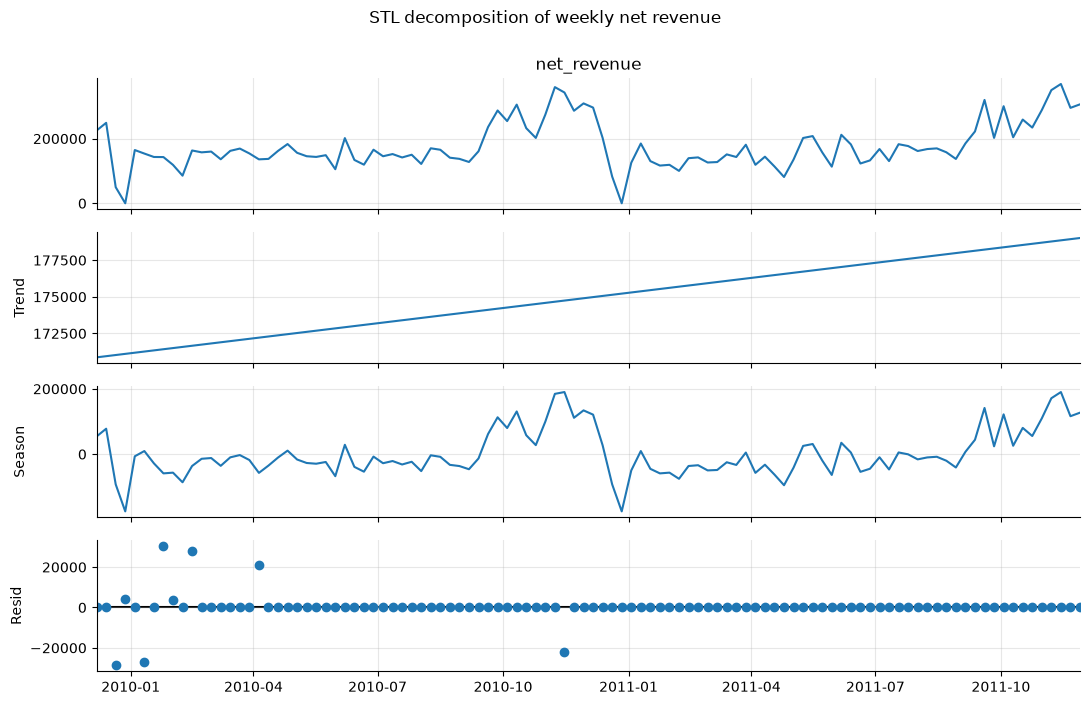

STL trend change over the period: +4.8% (indicative only)


In [8]:
stl = STL(w, period=52, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7)
fig.suptitle("STL decomposition of weekly net revenue", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "bq2_stl.png", dpi=150)
plt.show()

trend_change = stl.trend.iloc[-1] / stl.trend.iloc[0] - 1
print(f"STL trend change over the period: {trend_change:+.1%} (indicative only)")

## BQ2: Autocorrelation

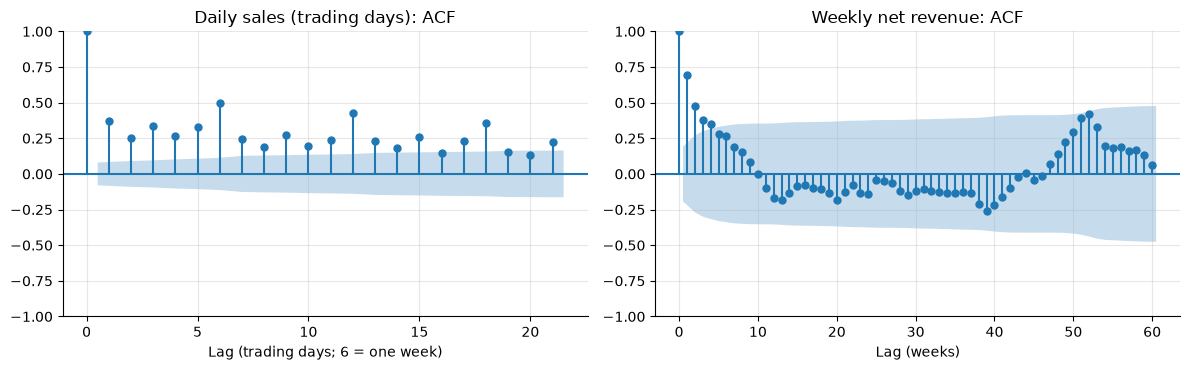

In [9]:
daily = prod.groupby("date")["revenue"].sum()
daily = daily.loc[daily.index < "2011-12-01"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(daily, lags=21, ax=axes[0], title="Daily sales (trading days): ACF")
plot_acf(w, lags=60, ax=axes[1], title="Weekly net revenue: ACF")
axes[0].set_xlabel("Lag (trading days; 6 = one week)")
axes[1].set_xlabel("Lag (weeks)")
fig.tight_layout(); fig.savefig(FIG / "bq2_acf.png", dpi=150)
plt.show()

## BQ2: Month, weekday and hour patterns
Saturday is excluded: its only sales are a one-off opening on 5 Dec 2009.

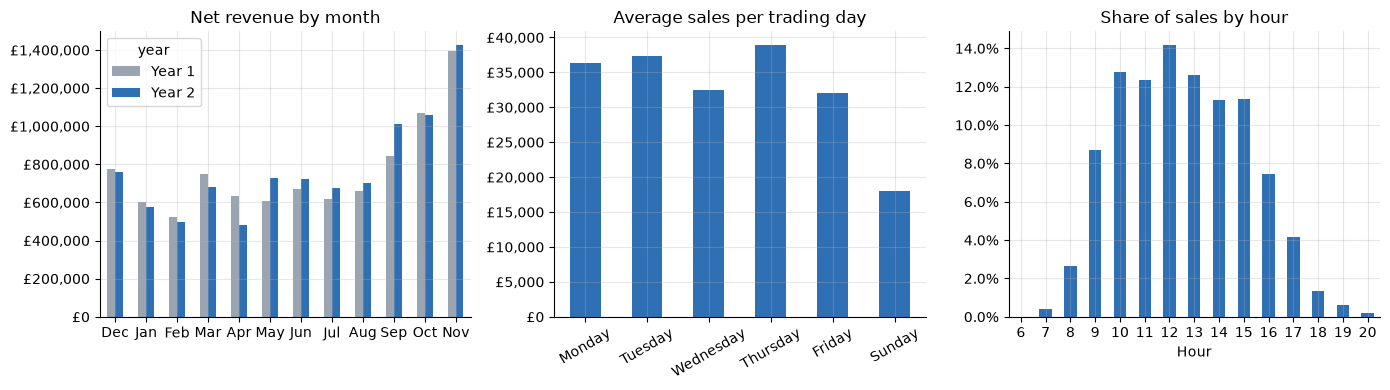

Q4 (Oct-Dec) share of net revenue: 35.1%

Average sales per trading day:
weekday
Monday       £36,347
Tuesday      £37,309
Wednesday    £32,455
Thursday     £38,934
Friday       £31,986
Sunday       £18,032
dtype: object

Busiest hours (top 3): [12, 10, 13]


In [10]:
m = monthly.copy()
m["year"] = np.where(m.index < "2010-12-01", "Year 1", "Year 2")
m["month_name"] = m.index.strftime("%b")
order = ["Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov"]
by_month = m.pivot(index="month_name", columns="year", values="net_revenue").reindex(order)

trading_days = prod.groupby("weekday")["date"].nunique()
by_weekday = (prod.groupby("weekday")["revenue"].sum() / trading_days).reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"])
by_hour = prod.groupby("hour")["revenue"].sum()
by_hour = by_hour / by_hour.sum()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
by_month.plot(kind="bar", ax=axes[0], color=["#9AA5B1", "#2F6FB3"], rot=0)
axes[0].set_title("Net revenue by month"); axes[0].set_xlabel("")
axes[0].yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
by_weekday.plot(kind="bar", ax=axes[1], color="#2F6FB3", rot=30)
axes[1].set_title("Average sales per trading day"); axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
by_hour.plot(kind="bar", ax=axes[2], color="#2F6FB3", rot=0)
axes[2].set_title("Share of sales by hour"); axes[2].set_xlabel("Hour")
axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
fig.tight_layout(); fig.savefig(FIG / "bq2_seasonal_patterns.png", dpi=150)
plt.show()

peak = by_month.sum(axis=1)
print("Q4 (Oct-Dec) share of net revenue:",
      f"{peak.loc[['Oct', 'Nov', 'Dec']].sum() / peak.sum():.1%}")
print("\nAverage sales per trading day:")
print(by_weekday.map("£{:,.0f}".format))
print(f"\nBusiest hours (top 3): {by_hour.nlargest(3).index.tolist()}")

## Saturday check

In [11]:
sat = sales.loc[sales["weekday"] == "Saturday"]
print(f"Saturday sales lines: {len(sat):,} on {sat['date'].nunique()} dates")
print(sat.groupby("date").size().sort_values(ascending=False).head(10))

Saturday sales lines: 400 on 1 dates
date
2009-12-05    400
dtype: int64


In [12]:
# Summary tables for the Looker Studio dashboard
DASH = ROOT / "reports" / "dashboard_data"
DASH.mkdir(parents=True, exist_ok=True)

monthly_out = monthly[["net_revenue", "gross_sales", "cancellations", "orders",
                       "customers", "avg_order_value", "cancel_rate"]].copy()
monthly_out.index.name = "month"
monthly_out.round(2).to_csv(DASH / "monthly_kpis.csv")

weekly_out = pd.DataFrame({
    "net_revenue": w,
    "ma_4wk": w.rolling(4).mean(),
    "ma_13wk_centred": w.rolling(13, center=True).mean(),
    "moving_annual_total": w.rolling(52).sum(),
})
weekly_out.index.name = "week_start"
weekly_out.round(2).to_csv(DASH / "weekly_revenue.csv")

by_weekday.rename("sales_per_trading_day").round(2).to_csv(DASH / "weekday_pattern.csv")
by_hour.rename("share_of_sales").round(4).to_csv(DASH / "hour_pattern.csv")

for f in sorted(DASH.glob("*.csv")):
    print(f"{f.name:<22} {len(pd.read_csv(f)):>4} rows")

hour_pattern.csv         15 rows
monthly_kpis.csv         24 rows
weekday_pattern.csv       6 rows
weekly_revenue.csv      104 rows
